# Taller — Abandono de producto financiero
Regresión logística en Python · Clase 9 · Machine Learning aplicado a Economía y Finanzas · FCEA · 2026-2

**Juan Diego Zutta Arcos**

Pregunta: dadas las características del cliente, ¿cuál es $P(\text{abandono}=1 \mid x)$? Se estima con `smf.logit` (y `smf.ols` como contraste), partición 70/30 con `default_rng(8)`.

## 1. Estructura de los datos

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy.stats import chi2_contingency

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)

df_crudo = pd.read_csv("abandono_producto_financiero.csv", encoding="utf-8")
print("Dimensión cruda:", df_crudo.shape)
df_crudo.head()

Dimensión cruda: (10000, 14)


,numero_fila,id_cliente,apellido,puntaje_crediticio,pais,sexo,edad,antiguedad,saldo,numero_productos,tiene_tarjeta,miembro_activo,salario_estimado,abandono
0,1,15634602,Hargrave,619,Francia,Mujer,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,España,Mujer,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,Francia,Mujer,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,Francia,Mujer,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,España,Mujer,43,2,125510.82,1,1,1,79084.10,0


In [2]:
print(list(df_crudo.columns))
df_crudo.dtypes

['numero_fila', 'id_cliente', 'apellido', 'puntaje_crediticio', 'pais', 'sexo', 'edad', 'antiguedad', 'saldo', 'numero_productos', 'tiene_tarjeta', 'miembro_activo', 'salario_estimado', 'abandono']


numero_fila             int64
id_cliente              int64
apellido                  str
puntaje_crediticio      int64
pais                      str
sexo                      str
edad                    int64
antiguedad              int64
saldo                 float64
numero_productos        int64
tiene_tarjeta           int64
miembro_activo          int64
salario_estimado      float64
abandono                int64
dtype: object

In [3]:
df_crudo.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
numero_fila,10000.0,5000.50,2886.90,1.00,2500.75,5000.50,7500.25,10000.00
id_cliente,10000.0,15690940.57,71936.19,15565701.00,15628528.25,15690738.00,15753233.75,15815690.00
puntaje_crediticio,10000.0,650.53,96.65,350.00,584.00,652.00,718.00,850.00
edad,10000.0,38.92,10.49,18.00,32.00,37.00,44.00,92.00
antiguedad,10000.0,5.01,2.89,0.00,3.00,5.00,7.00,10.00
saldo,10000.0,76485.89,62397.41,0.00,0.00,97198.54,127644.24,250898.09
numero_productos,10000.0,1.53,0.58,1.00,1.00,1.00,2.00,4.00
tiene_tarjeta,10000.0,0.71,0.46,0.00,0.00,1.00,1.00,1.00
miembro_activo,10000.0,0.52,0.50,0.00,0.00,1.00,1.00,1.00
salario_estimado,10000.0,100090.24,57510.49,11.58,51002.11,100193.92,149388.25,199992.48


In [4]:
df = df_crudo.drop(columns=["numero_fila", "id_cliente", "apellido"]).copy()
df["pais"] = pd.Categorical(df["pais"], categories=["Francia", "Alemania", "España"])
df["sexo"] = pd.Categorical(df["sexo"], categories=["Mujer", "Hombre"])
df["abandono"] = df["abandono"].astype(int)

cuantitativas = ["puntaje_crediticio", "edad", "antiguedad", "saldo", "numero_productos", "salario_estimado"]
categoricas_binarias = ["pais", "sexo", "tiene_tarjeta", "miembro_activo", "abandono"]
print("Dimensión para el modelo:", df.shape)
print("Cuantitativas (", len(cuantitativas), "):", cuantitativas)
print("Categóricas o binarias (", len(categoricas_binarias), "):", categoricas_binarias)
print("Niveles de pais:", list(df["pais"].cat.categories), "· de sexo:", list(df["sexo"].cat.categories))
print("Faltantes totales:", int(df.isna().sum().sum()))
df.dtypes

Dimensión para el modelo: (10000, 11)
Cuantitativas ( 6 ): ['puntaje_crediticio', 'edad', 'antiguedad', 'saldo', 'numero_productos', 'salario_estimado']
Categóricas o binarias ( 5 ): ['pais', 'sexo', 'tiene_tarjeta', 'miembro_activo', 'abandono']
Niveles de pais: ['Francia', 'Alemania', 'España'] · de sexo: ['Mujer', 'Hombre']
Faltantes totales: 0


puntaje_crediticio       int64
pais                  category
sexo                  category
edad                     int64
antiguedad               int64
saldo                  float64
numero_productos         int64
tiene_tarjeta            int64
miembro_activo           int64
salario_estimado       float64
abandono                 int64
dtype: object

### Respuestas — Sección 1

**1. ¿Cuántas variables tiene la base cruda? ¿Cuántas quedan para el modelo?**
La base cruda tiene **14 variables** y 10.000 clientes. Al quitar los tres identificadores (`numero_fila`, `id_cliente`, `apellido`) quedan **11 variables**: 10 explicativas y la respuesta `abandono`. No hay valores faltantes.

**2. ¿Cuántas son cuantitativas?**
**6**: `puntaje_crediticio`, `edad`, `antiguedad`, `saldo`, `numero_productos` y `salario_estimado`. `numero_productos` es un entero, pero el diccionario lo trata como continuo.

**3. ¿Cuántas son categóricas o binarias (incluyendo `abandono`)?**
**5**: dos categóricas (`pais` con 3 niveles y `sexo` con 2) y tres binarias 0/1 (`tiene_tarjeta`, `miembro_activo` y `abandono`).

**4. ¿Qué implica esta mezcla para el logit en Python?**
Las binarias 0/1 y las cuantitativas entran tal cual: su coeficiente es el cambio en log-odds por una unidad. Las categóricas de texto no se pueden multiplicar por un coeficiente. `C(pais)` y `C(sexo)` le piden a la fórmula que cree las dummies automáticamente, dejando por fuera la **categoría de referencia** (Francia y Mujer, porque son el primer nivel del `category`). Así se evita la trampa de las dummies (colinealidad perfecta con el intercepto) y cada coeficiente se lee contra la referencia. Hacer las dummies a mano exige crear k−1 columnas, elegir la referencia y repetir exactamente lo mismo al predecir sobre datos nuevos. Con `C()` el mismo `predict` aplica la codificación a `Test_Data` o a un perfil inventado.

## 2. Descriptivo univariado

          conteo  proporción
abandono                    
0           7963      0.7963
1           2037      0.2037


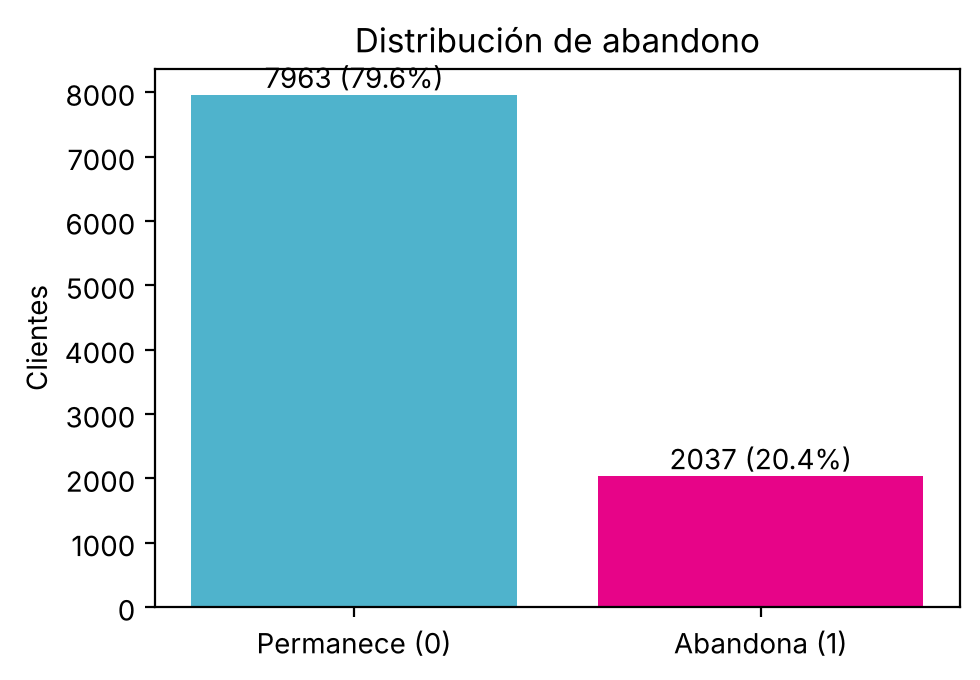

In [5]:
conteo = df["abandono"].value_counts().sort_index()
proporcion = df["abandono"].value_counts(normalize=True).sort_index()
print(pd.DataFrame({"conteo": conteo, "proporción": proporcion.round(4)}))

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.bar(["Permanece (0)", "Abandona (1)"], conteo.values, color=["#4FB3CC", "#E70488"])
for i, v in enumerate(conteo.values):
    ax.text(i, v, f"{v} ({proporcion.values[i]:.1%})", ha="center", va="bottom")
ax.set_title("Distribución de abandono")
ax.set_ylabel("Clientes")
plt.tight_layout(); plt.show()

                      count       mean       std     min       25%        50%        75%        max
edad                10000.0      38.92     10.49   18.00     32.00      37.00      44.00      92.00
puntaje_crediticio  10000.0     650.53     96.65  350.00    584.00     652.00     718.00     850.00
saldo               10000.0   76485.89  62397.41    0.00      0.00   97198.54  127644.24  250898.09
salario_estimado    10000.0  100090.24  57510.49   11.58  51002.11  100193.92  149388.25  199992.48


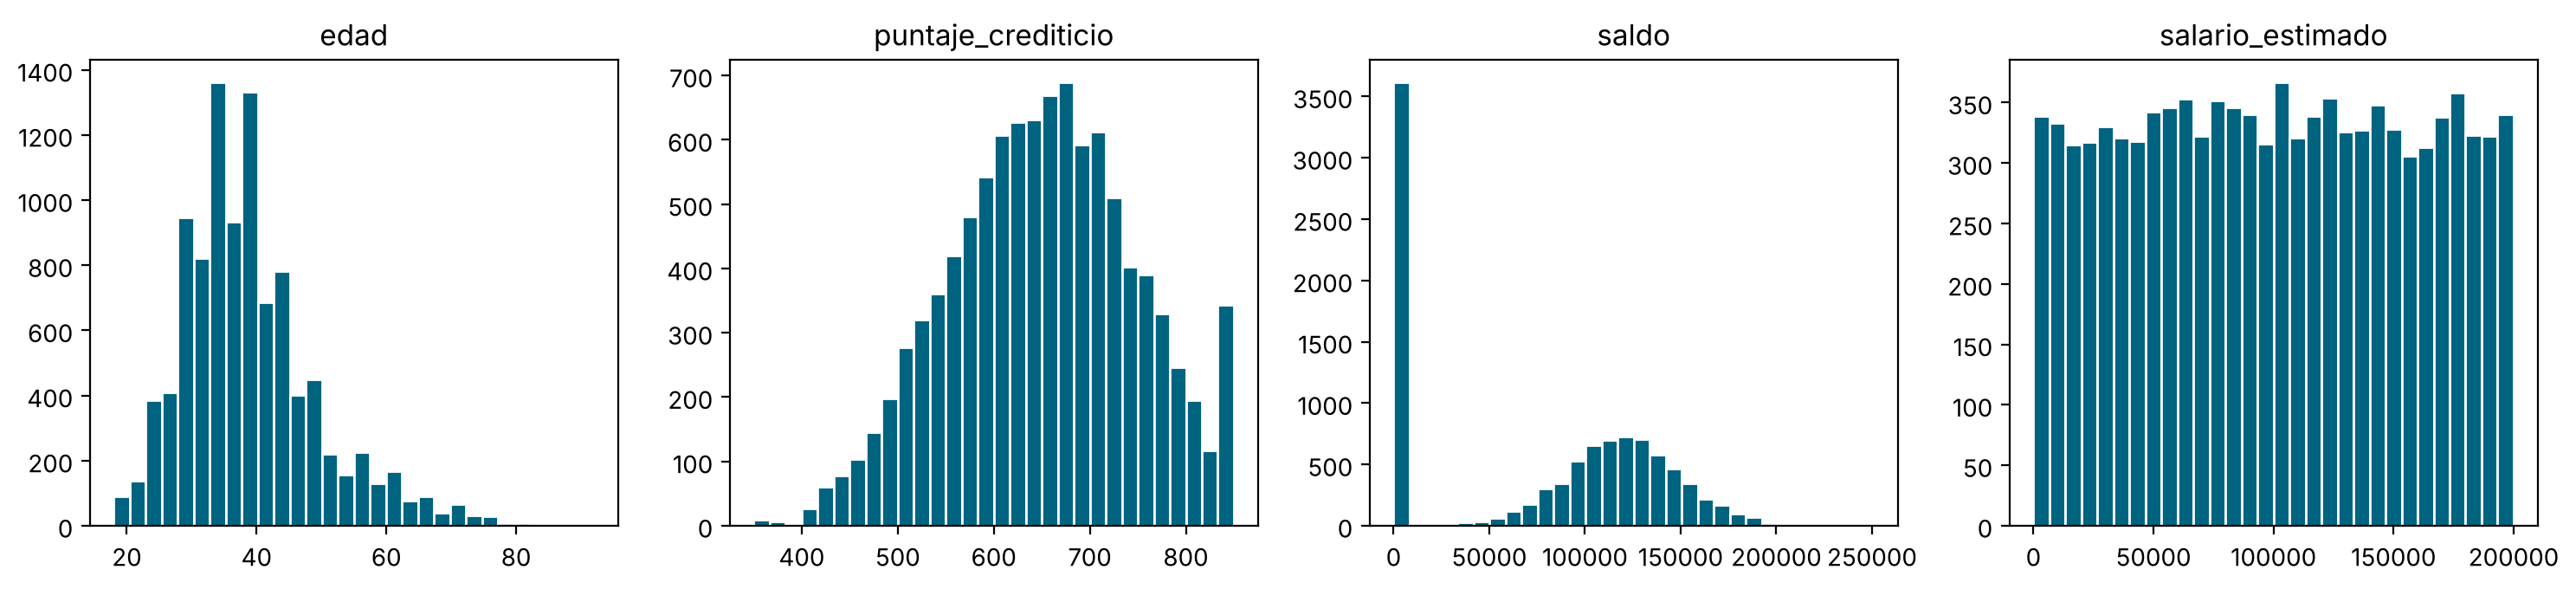

Clientes con saldo = 0: 3617 (36.2%)


In [6]:
continuas = ["edad", "puntaje_crediticio", "saldo", "salario_estimado"]
print(df[continuas].describe().T.round(2))

fig, ejes = plt.subplots(1, 4, figsize=(15, 3.5))
for ax, v in zip(ejes, continuas):
    ax.hist(df[v], bins=30, color="#00637F", edgecolor="white")
    ax.set_title(v)
plt.tight_layout(); plt.show()

print("Clientes con saldo = 0:", int((df["saldo"] == 0).sum()), f"({(df['saldo'] == 0).mean():.1%})")

In [7]:
for v in ["pais", "sexo", "numero_productos", "miembro_activo"]:
    t = pd.DataFrame({"conteo": df[v].value_counts().sort_index(),
                      "proporción": df[v].value_counts(normalize=True).sort_index().round(4)})
    print(f"--- {v} ---")
    print(t, "\n")

--- pais ---
          conteo  proporción
pais                        
Francia     5014      0.5014
Alemania    2509      0.2509
España      2477      0.2477 

--- sexo ---
        conteo  proporción
sexo                      
Mujer     4543      0.4543
Hombre    5457      0.5457 

--- numero_productos ---
                  conteo  proporción
numero_productos                    
1                   5084      0.5084
2                   4590      0.4590
3                    266      0.0266
4                     60      0.0060 

--- miembro_activo ---
                conteo  proporción
miembro_activo                    
0                 4849      0.4849
1                 5151      0.5151 



### Respuesta — Sección 2

**5. ¿Qué porcentaje de la base abandonó? ¿Por qué un clasificador que siempre diga «permanece» ya parece bueno si uno solo mira la *accuracy*?**
Abandonaron **2.037 de 10.000 clientes, el 20,4 %**. El 79,6 % permanece. Un clasificador que diga siempre «permanece» acierta en el 79,6 % de los casos sin usar ninguna variable. Esa exactitud parece alta, pero su sensibilidad es **0**: no detecta a ninguno de los clientes que se van, que son justamente los que le importan al área de retención. Con clases desbalanceadas, la exactitud premia acertar la clase mayoritaria. Por eso hay que mirarla junto con la sensibilidad y la especificidad (sección 6).

Otros rasgos del univariado: la edad tiene sesgo a la derecha (mediana 37, máximo 92). El saldo tiene una masa grande en cero (3.617 clientes, 36,2 %) y luego una campana alrededor de 120.000. El puntaje crediticio y el salario estimado no muestran nada raro: el salario es casi uniforme entre 0 y 200.000. Francia concentra la mitad de los clientes, y el 97 % de la base tiene 1 o 2 productos.

## 3. Bivariado con la respuesta

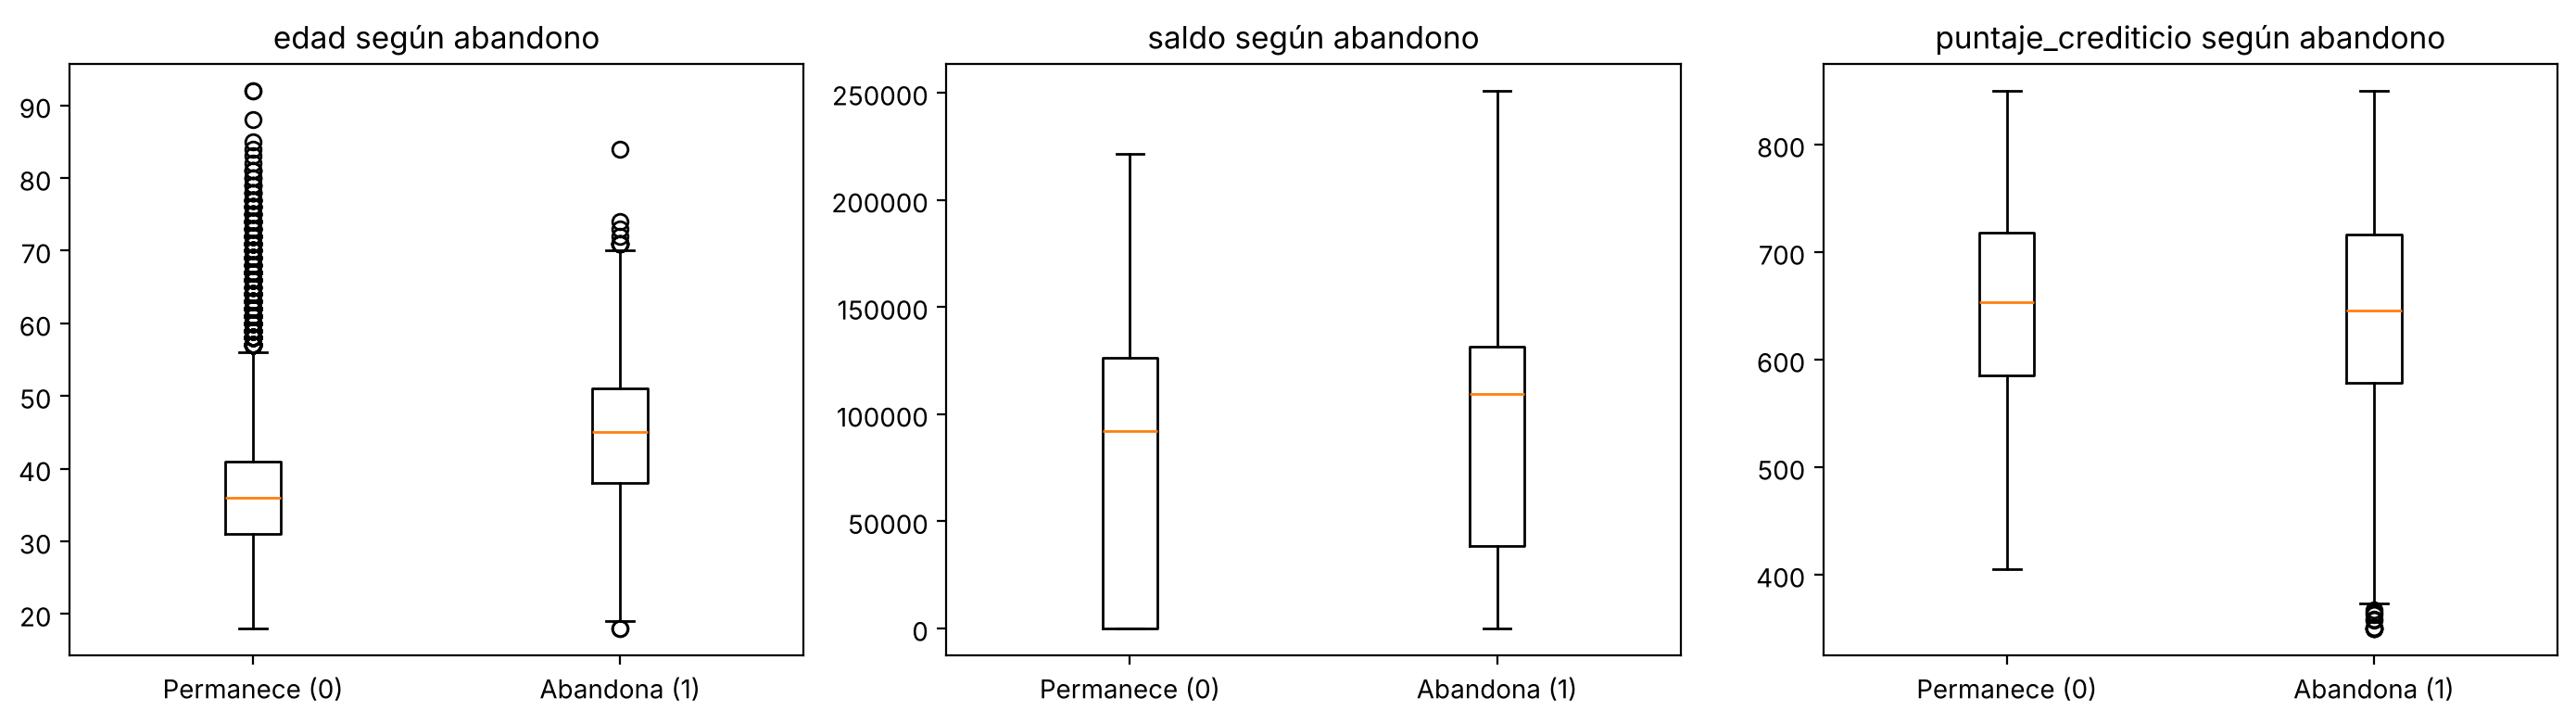

Medianas por grupo
          edad      saldo  puntaje_crediticio
abandono                                     
0         36.0   92072.68               653.0
1         45.0  109349.29               646.0

Medias por grupo
           edad     saldo  puntaje_crediticio
abandono                                     
0         37.41  72745.30              651.85
1         44.84  91108.54              645.35


In [8]:
fig, ejes = plt.subplots(1, 3, figsize=(14, 4))
for ax, v in zip(ejes, ["edad", "saldo", "puntaje_crediticio"]):
    datos = [df.loc[df["abandono"] == k, v] for k in (0, 1)]
    ax.boxplot(datos, tick_labels=["Permanece (0)", "Abandona (1)"])
    ax.set_title(f"{v} según abandono")
plt.tight_layout(); plt.show()

print("Medianas por grupo")
print(df.groupby("abandono")[["edad", "saldo", "puntaje_crediticio"]].median())
print("\nMedias por grupo")
print(df.groupby("abandono")[["edad", "saldo", "puntaje_crediticio"]].mean().round(2))

In [9]:
print("Proporción con saldo 0 por grupo:")
print(df.groupby("abandono")["saldo"].apply(lambda s: (s == 0).mean()).round(3))
print("\nTasa de abandono por tramo de edad:")
tramos = pd.cut(df["edad"], bins=[17, 30, 40, 50, 60, 100], labels=["18-30", "31-40", "41-50", "51-60", "61+"])
print(df.groupby(tramos, observed=True)["abandono"].agg(["mean", "size"]).round(3))

Proporción con saldo 0 por grupo:
abandono
0    0.391
1    0.245
Name: saldo, dtype: float64

Tasa de abandono por tramo de edad:
        mean  size
edad              
18-30  0.075  1968
31-40  0.121  4451
41-50  0.340  2320
51-60  0.562   797
61+    0.248   464


In [10]:
resultados_chi2 = []
for v in ["miembro_activo", "numero_productos", "pais", "sexo", "tiene_tarjeta"]:
    tabla = pd.crosstab(df[v], df["abandono"])
    chi2, p, gl, _ = chi2_contingency(tabla)
    n = tabla.values.sum()
    v_cramer = np.sqrt(chi2 / (n * (min(tabla.shape) - 1)))
    resultados_chi2.append({"variable": v, "chi2": round(chi2, 1), "gl": gl, "p_valor": p, "V_Cramer": round(v_cramer, 3)})
    print(f"--- {v} ---")
    print(pd.concat([tabla, pd.crosstab(df[v], df["abandono"], normalize="index").round(3)
                     .rename(columns={0: "% perm.", 1: "% aband."})], axis=1))
    print(f"chi2 = {chi2:.1f}, gl = {gl}, p = {p:.3g}\n")
pd.DataFrame(resultados_chi2).sort_values("chi2", ascending=False)

--- miembro_activo ---
abandono           0     1  % perm.  % aband.
miembro_activo                               
0               3547  1302    0.731     0.269
1               4416   735    0.857     0.143
chi2 = 243.0, gl = 1, p = 8.79e-55

--- numero_productos ---
abandono             0     1  % perm.  % aband.
numero_productos                               
1                 3675  1409    0.723     0.277
2                 4242   348    0.924     0.076
3                   46   220    0.173     0.827
4                    0    60    0.000     1.000
chi2 = 1503.6, gl = 3, p = 0

--- pais ---
abandono     0    1  % perm.  % aband.
pais                                  
Francia   4204  810    0.838     0.162
Alemania  1695  814    0.676     0.324
España    2064  413    0.833     0.167
chi2 = 301.3, gl = 2, p = 3.83e-66

--- sexo ---
abandono     0     1  % perm.  % aband.
sexo                                   
Mujer     3404  1139    0.749     0.251
Hombre    4559   898    0.835     0.1

,variable,chi2,gl,p_valor,V_Cramer
1,numero_productos,1503.6,3,0.000000e+00,0.388
2,pais,301.3,2,3.830318e-66,0.174
0,miembro_activo,243.0,1,8.785858e-55,0.156
3,sexo,112.9,1,2.248210e-26,0.106
4,tiene_tarjeta,0.5,1,4.923724e-01,0.007


### Respuestas — Sección 3

**6. Distribución de edad entre quien abandona y quien permanece.**
Quien abandona es claramente mayor. La mediana de edad es **45 años** entre los que se van y **36** entre los que se quedan (medias 44,8 y 37,4). En el *boxplot*, la caja de los que abandonan está desplazada hacia arriba: su cuartil inferior (38 años) queda por encima de la mediana de los que permanecen (36), y su cuartil superior llega a 51 frente a 41. Por tramos, la tasa de abandono sube de 7,5 % (18–30 años) a 12,1 % (31–40), 34,0 % (41–50) y **56,2 % (51–60)**, y vuelve a bajar a 24,8 % después de los 60. La relación es fuerte pero no lineal.

**7. Saldo y puntaje crediticio entre los dos grupos.**
- **Saldo:** quien abandona tiene más saldo. La mediana es 109.349 frente a 92.073 y la media 91.109 frente a 72.745. Parte de la diferencia viene de los saldos en cero: el 39,1 % de los que permanecen tiene saldo 0, frente al 24,5 % de los que se van. Los *boxplots* se solapan bastante.
- **Puntaje crediticio:** prácticamente igual. Mediana de 646 entre los que abandonan y 653 entre los que permanecen (medias 645 y 652), con cajas casi idénticas. El puntaje discrimina muy poco.

**8. `miembro_activo` y abandono.**
Sí: los clientes activos abandonan menos. Entre los inactivos la tasa es **26,9 %** y entre los activos **14,3 %**, casi la mitad. El ji-cuadrado es 243,0 con 1 gl (p ≈ 9·10⁻⁵⁵), así que la asociación no es azar.

**9. `numero_productos` y abandono. ¿Más productos se asocia siempre con menos abandono?**
**No.** La relación tiene forma de U. Con 1 producto abandona el **27,7 %**, con 2 baja a **7,6 %**, pero con 3 sube a **82,7 %** y con 4 llega al **100 %** (60 de 60). Pasar de 1 a 2 productos protege; tener 3 o 4 se asocia con abandono casi seguro, aunque esos grupos son pequeños (266 y 60 clientes). El ji-cuadrado es 1.503,6 con 3 gl (p ≈ 0).

**10. ¿Qué variable parece tener mayor relación con el abandono?**
Entre las categóricas, **`numero_productos`**: tiene el ji-cuadrado más alto (1.503,6) y la mayor V de Cramér (0,39), frente a `pais` (301,3; V = 0,17), `miembro_activo` (243,0; V = 0,16) y `sexo` (112,9; V = 0,11). Las tasas van de 7,6 % a 100 % según el número de productos. `tiene_tarjeta` no tiene relación (20,8 % frente a 20,2 %; p = 0,49). Entre las continuas, la **edad** es la que más separa a los grupos: 9 años de diferencia en la mediana y tasas de 7,5 % a 56,2 % por tramo. En el logit simple su z es 26,6. El puntaje crediticio casi no separa.

## 4. De la recta al logit

Intercept   -0.22278
edad         0.01096
dtype: float64
             Coef.  Std.Err.         z  P>|z|   [0.025   0.975]
Intercept -3.92860   0.10312 -38.09595    0.0 -4.13072 -3.72648
edad       0.06294   0.00237  26.61413    0.0  0.05831  0.06758


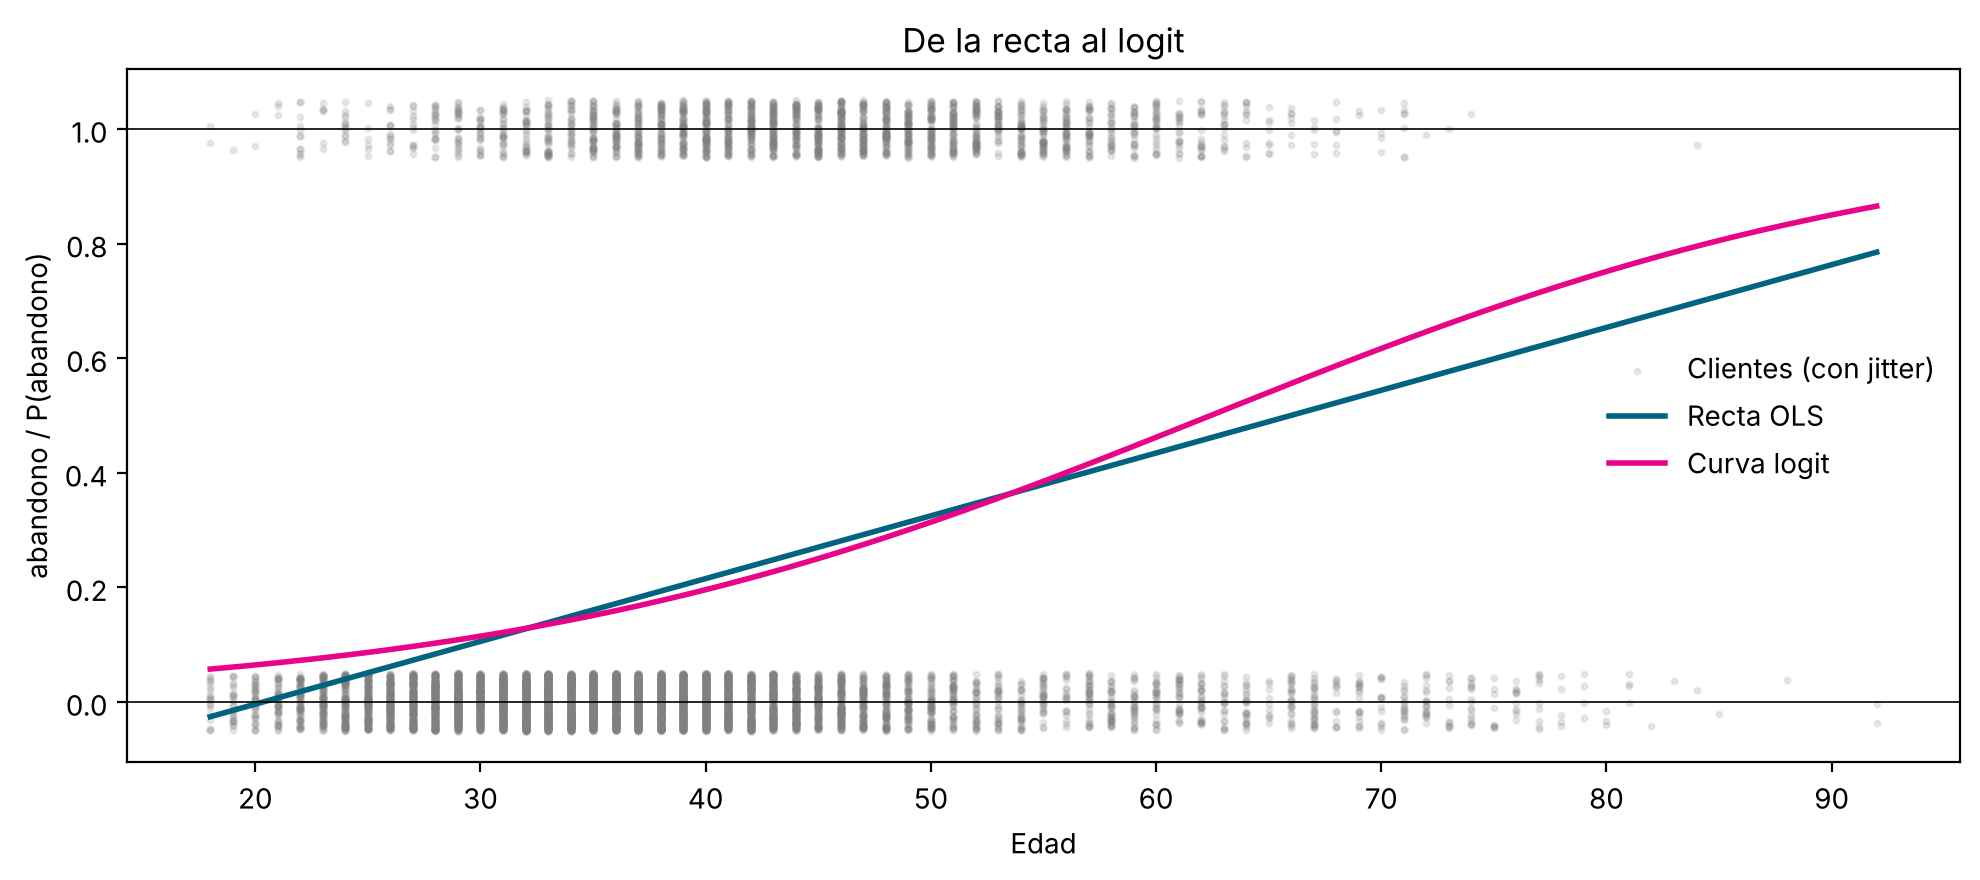

OLS: predicción mínima -0.026 · máxima 0.785
OLS: edad donde la recta cruza 0: 20.3


In [11]:
ols_edad = smf.ols("abandono ~ edad", data=df).fit()
logit_edad = smf.logit("abandono ~ edad", data=df).fit(disp=0)
print(ols_edad.params.round(5))
print(logit_edad.summary2().tables[1].round(5))

rejilla = pd.DataFrame({"edad": np.linspace(df["edad"].min(), df["edad"].max(), 200)})
rng_jitter = np.random.default_rng(0)
y_jitter = df["abandono"] + rng_jitter.uniform(-0.05, 0.05, len(df))

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.scatter(df["edad"], y_jitter, s=4, alpha=0.15, color="grey", label="Clientes (con jitter)")
ax.plot(rejilla["edad"], ols_edad.predict(rejilla), color="#00637F", lw=2, label="Recta OLS")
ax.plot(rejilla["edad"], logit_edad.predict(rejilla), color="#E70488", lw=2, label="Curva logit")
ax.axhline(0, color="black", lw=0.6); ax.axhline(1, color="black", lw=0.6)
ax.set_xlabel("Edad"); ax.set_ylabel("abandono / P(abandono)")
ax.set_title("De la recta al logit")
ax.legend(frameon=False); plt.tight_layout(); plt.show()

pred_ols = ols_edad.predict(rejilla)
print("OLS: predicción mínima", round(pred_ols.min(), 3), "· máxima", round(pred_ols.max(), 3))
print("OLS: edad donde la recta cruza 0:", round(-ols_edad.params["Intercept"] / ols_edad.params["edad"], 1))

In [12]:
b0, b1 = logit_edad.params["Intercept"], logit_edad.params["edad"]
print("Intercepto:", round(b0, 4))
print("Coeficiente de edad:", round(b1, 4))
print("Odds ratio de edad:", round(np.exp(b1), 4))
print("Odds ratio por 10 años:", round(np.exp(10 * b1), 3))
p40 = float(logit_edad.predict(pd.DataFrame({"edad": [40]}))[0])
print("P(abandono | edad = 40):", round(p40, 4))
print("Comprobación a mano:", round(np.exp(b0 + 40 * b1) / (1 + np.exp(b0 + 40 * b1)), 4))

Intercepto: -3.9286
Coeficiente de edad: 0.0629
Odds ratio de edad: 1.065
Odds ratio por 10 años: 1.877
P(abandono | edad = 40): 0.1961
Comprobación a mano: 0.1961


### Respuestas — Sección 4

**11. ¿Por qué la recta de mínimos cuadrados no puede leerse como una probabilidad?**
Porque la recta no está acotada entre 0 y 1. Aquí $\hat y = -0{,}223 + 0{,}011\,\text{edad}$ da valores **negativos para clientes menores de 20,3 años** (−0,026 a los 18). Si la edad sigue subiendo, terminaría pasando de 1. Además, impone un efecto constante: cada año suma 1,1 puntos de probabilidad sin importar si el cliente tiene 20 o 60 años. Los datos muestran otra cosa: la tasa casi no se mueve entre los jóvenes y se dispara entre los 40 y los 60. Los errores de un modelo lineal con y binaria tampoco tienen varianza constante. El logit pasa la combinación lineal por $\Lambda(\cdot)$ y siempre devuelve un valor en (0, 1), con la curva en S del gráfico.

**12. Intercepto, coeficiente de edad y *odds ratio* del logit simple.**
- Intercepto: **−3,9286**
- Coeficiente de edad: **0,0629** (z = 26,6, p < 0,001)
- *Odds ratio*: $e^{0{,}0629}$ = **1,065**

En una frase de negocio: **por cada año adicional de edad, los *odds* de que un cliente cierre su relación con el banco aumentan cerca de 6,5 %**. Diez años más casi duplican los *odds* (OR = 1,88).

**13. P(abandono) para un cliente de 40 años.**
$P = \dfrac{e^{-3{,}9286 + 0{,}0629 \times 40}}{1 + e^{-3{,}9286 + 0{,}0629 \times 40}}$ = **0,196**, es decir, cerca de **19,6 %**. Está muy cerca de la tasa promedio de la base (20,4 %), porque 40 años es una edad algo superior a la media (38,9).